In [1]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

EXP = 'exp/q1'

def load_eval(run_dir, max_step=1000000):
    data = pickle.load(open(f'{EXP}/{run_dir}/log.pkl', 'rb'))
    rows = [r for r in data['eval'] if r['step'] <= max_step]
    steps = [r['step'] for r in rows]
    sr = [r['eval/success_rate'] for r in rows]
    return np.array(steps), np.array(sr)

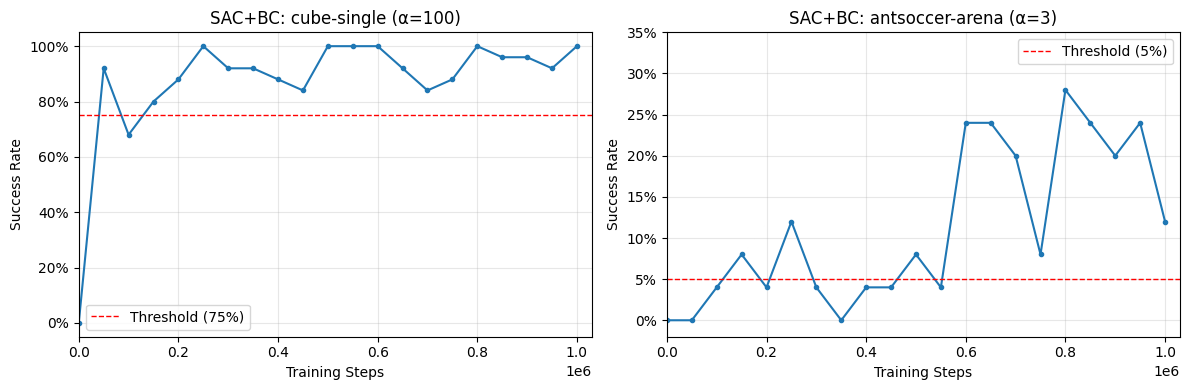

In [2]:
# Plot 1: Best SAC+BC agents on cube-single and antsoccer
best_cube  = 'sd0_20260403_200454_sacbc_cube-single-play-singletask-task1-v0_a100.0'
best_ants  = 'sd0_20260403_200438_sacbc_antsoccer-arena-navigate-singletask-task1-v0_a3.0'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, run, title, threshold, ylim in [
    (axes[0], best_cube, 'cube-single (α=100)', 0.75, (-0.05, 1.05)),
    (axes[1], best_ants, 'antsoccer-arena (α=3)', 0.05, (-0.02, 0.35)),
]:
    steps, sr = load_eval(run)
    ax.plot(steps, sr, marker='o', markersize=3, linewidth=1.5)
    ax.axhline(threshold, color='red', linestyle='--', linewidth=1, label=f'Threshold ({threshold:.0%})')
    ax.set_xlabel('Training Steps')
    ax.set_ylabel('Success Rate')
    ax.set_title(f'SAC+BC: {title}')
    ax.set_xlim(0, 1030000)
    ax.set_ylim(ylim)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sacbc_best_agents.png', dpi=150, bbox_inches='tight')
plt.show()

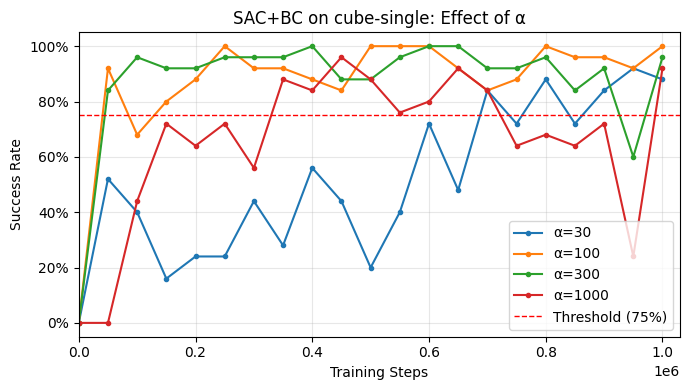

In [3]:
# Plot 2: cube-single with different alpha values
alpha_runs = {
    'α=30':   'sd0_20260403_200454_sacbc_cube-single-play-singletask-task1-v0_a30.0',
    'α=100':  'sd0_20260403_200454_sacbc_cube-single-play-singletask-task1-v0_a100.0',
    'α=300':  'sd0_20260403_200454_sacbc_cube-single-play-singletask-task1-v0_a300.0',
    'α=1000': 'sd0_20260403_200454_sacbc_cube-single-play-singletask-task1-v0_a1000.0',
}

fig, ax = plt.subplots(figsize=(7, 4))

for label, run in alpha_runs.items():
    steps, sr = load_eval(run)
    ax.plot(steps, sr, marker='o', markersize=3, linewidth=1.5, label=label)

ax.axhline(0.75, color='red', linestyle='--', linewidth=1, label='Threshold (75%)')
ax.set_xlabel('Training Steps')
ax.set_ylabel('Success Rate')
ax.set_title('SAC+BC on cube-single: Effect of α')
ax.set_xlim(0, 1030000)
ax.set_ylim(-0.05, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sacbc_alpha_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

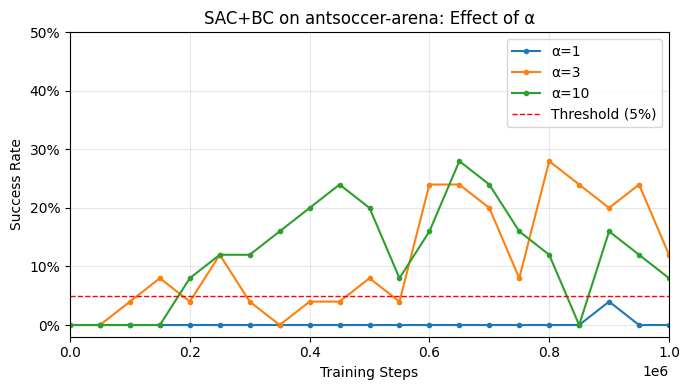

In [5]:
# Plot 3: antsoccer with different alpha values
alpha_runs_ants = {
    'α=1':  'sd0_20260403_200438_sacbc_antsoccer-arena-navigate-singletask-task1-v0_a1.0',
    'α=3':  'sd0_20260403_200438_sacbc_antsoccer-arena-navigate-singletask-task1-v0_a3.0',
    'α=10': 'sd0_20260403_200438_sacbc_antsoccer-arena-navigate-singletask-task1-v0_a10.0',
}

fig, ax = plt.subplots(figsize=(7, 4))

for label, run in alpha_runs_ants.items():
    steps, sr = load_eval(run)
    ax.plot(steps, sr, marker='o', markersize=3, linewidth=1.5, label=label)

ax.axhline(0.05, color='red', linestyle='--', linewidth=1, label='Threshold (5%)')
ax.set_xlabel('Training Steps')
ax.set_ylabel('Success Rate')
ax.set_title('SAC+BC on antsoccer-arena: Effect of α')
ax.set_xlim(0, 1000000)
ax.set_ylim(-0.02, 0.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sacbc_antsoccer_alpha_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
